# 18 · 여러 형상의 비용 합치기 — min, sum, max

## 질문과 최종 목적

> **질문:** 사람 몸은 형상(원·캡슐) 여러 개로 나타낸다. 형상마다 거리-활성 거리 비용(η 비용)을 하나씩 계산했을 때, 이것을 (a) 가장 가까운 형상 하나(min), (b) 모두 더하기(sum), (c) 가장 큰 것(max) 중 어떤 방법으로 합치느냐에 따라 비용 지형과 MPPI 회피는 어떻게 달라지는가?
>
> **최종 목적:** 프로젝트(franka-depth-mppi)가 형상 비용을 max로 합치는 이유를 이 노트의 장면에서 직접 확인한다.

| | |
|---|---|
| **최종 목표** | 세 방식의 비용 지형을 그려 차이를 말할 수 있다. min에서 비용이 뛰는 곳과 그 이유(몸통 그림자)를 설명할 수 있다. sum이 형상을 나누는 방식에 따라 달라지는 것(중복 계산)을 수치로 보일 수 있다. MPPI 회피에서 세 방식의 차이를 같은 seed끼리 비교해 말할 수 있다 |
| **연구의 어느 결정과 연결되는가** | 프로젝트의 형상 비용 합치기 방식(기본 max_all, 비교용 nearest). 16의 "몸통 그늘", 17의 해상도 |
| **이 노트에서 바꾸는 요인** | 형상 비용을 합치는 방식 하나(min / sum / max). 3절에서만 같은 몸통을 캡슐 몇 개로 나누는지도 바꾼다 |
| **바꾸지 않는 것** | η 비용 식, w = 100, MPPI 설정(K 400, σ 2, β 1, 반복 5, 가중평균), 시작·목표, 사람 정지 |

**지금 위치:** 01~13 기초·MPPI·프로젝트 → 14 움직이는 사람 → 15 η와 w → 16 방향별 질량 → 17 ESS → **18 형상 비용 합치기** → 19 필요 이격 거리 → 20 안전 필터 → 21 지연 → 22 cuRobo 확인

**필요한 것:** [15](15_eta_vs_weight.ipynb) η 비용, [16](16_directional_mass.ipynb) 질량 → η 규칙((iii))과 몸통 그늘, [17](17_ess.ipynb) ESS와 같은 seed 비교 · **예상 시간:** 45분

### 이 노트의 가설
1. min은 "가장 가까운 형상"이 바뀌는 선에서 비용 값이 뛴다. max와 sum은 이어진다.
2. 같은 몸통을 캡슐 여러 개로 나누면 sum만 커지고, min과 max는 그대로다.
3. MPPI에서 min은 몸통 그림자 때문에 max·sum보다 몸통에 더 가까이 지나간다.
4. min의 비용이 뛰는 곳 근처에서 ESS가 줄고 명령이 더 흔들린다.

## 복습 퀴즈

<details><summary>1. 16의 기준 자세에서 팔의 방향별 질량 효과가 나오지 않은 직접 원인은?</summary>

**몸통 그늘.** 가장 가까운 분절 하나만 보는 비용에서, 팔이 몸통 비용 영역 안쪽에 있어 팔이 가장 가까운 분절이 되는 일이 없었다. 그래서 팔의 η가 비용에 한 번도 쓰이지 않았다. 이 노트에서는 반대 경우(가벼운 손이 가장 가까워 무거운 몸통의 η가 가려짐)를 본다.
</details>

<details><summary>2. 17에서 η 차이가 만든 이격 차이(약 1 cm)가 seed 범위에 묻혔을 때, 효과의 방향은 어떻게 확인했나?</summary>

**같은 seed끼리 짝지어 비교했다.** 범위는 겹쳤지만 16개 중 15~16개 seed에서 같은 방향이었다. 이 노트도 같은 seed끼리 비교한다.
</details>

<details><summary>3. η 비용 c(d) = w(η − d)²/(2η) (0 ≤ d < η)는 d = η에서 값과 기울기가 어떻게 되나?</summary>

**값 0, 기울기 0.** 활성 거리 경계에서 비용이 매끄럽게 0으로 이어진다. cuRobo의 충돌 비용도 같은 식이다.
</details>

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # 노트 폴더 (common14 패키지)
import numpy as np
from functools import partial
from matplotlib.patches import Circle, Polygon
from common14 import *
from common14 import scene as S
from common14.shapes import capsule, shape_gaps, shape_costs, combine_cost, scene_shapes
plt = setup_plot()

# 18에서 추가한 common14.shapes가 기본값에서 14~17의 사람 비용과 같은지 확인
Pt = np.random.default_rng(1).uniform([-0.2, -0.5], [2.2, 0.6], (50, S.T, 2)); Z = np.zeros((S.T, 2))
print('기준 자세·균일 η: combine_cost(min)과 human_cost_uniform의 최대 차이 %.1e' % np.abs(combine_cost(Pt, Z, scene_shapes(), 'min') - human_cost_uniform(Pt, Z)).max())
r0, r1 = run_mpc_opts(), run_mpc_opts(partial(combine_cost, shapes=scene_shapes(), mode='min'))
print('같은 seed로 MPPI 실행: 궤적 최대 차이 %.1e m' % np.abs(r0['traj'] - r1['traj']).max())

기준 자세·균일 η: combine_cost(min)과 human_cost_uniform의 최대 차이 0.0e+00
같은 seed로 MPPI 실행: 궤적 최대 차이 0.0e+00 m


## 장면 — 손과 그 바로 뒤의 몸통

이 노트는 끝까지 장면 하나만 쓴다.
- **로봇:** 반지름 0.05 m의 점. (0, 0)에서 출발해 (2.0, 0)으로 가는 직선 길을 따라간다(14~17과 같음).
- **손 캡슐(가볍다):** 길 바로 옆, 길과 나란히 놓인 짧은 캡슐.
- **몸통 캡슐(무겁다):** 손 바로 뒤의 긴 캡슐. 손이 몸통 앞에 붙어 있고, 손 앞면이 몸통 앞면보다 4 cm 길 쪽으로 튀어나와 있다.

**형상**은 몸을 나타내는 원이나 캡슐 하나다. **간격**은 로봇 원 표면과 형상 표면 사이 거리다. 형상마다 η가 다르다. η는 16의 (iii) 규칙(η ∝ 환산질량 μ, 몸통 0.10 m 기준)으로 정한다. 손 쪽 질량은 16의 팔 수직(자유) 값 3 kg을 그대로 쓴다.

In [2]:
ex, ey = np.array([1.0, 0.0]), np.array([0.0, 1.0])
MU_T = float(reduced_mass(directional_mass(ex, 'torso')))     # 몸통 μ (15·16의 기준)
MU_H = float(reduced_mass(directional_mass(-ey, 'arm')))      # 손 쪽 μ (16의 팔 수직 자유 3 kg)
ETA_T = S.ETA0
ETA_H = S.ETA0 * MU_H / MU_T                                  # 16의 (iii): η ∝ μ

HAND = capsule((0.93, 0.115), (1.07, 0.115), S.ARM_R, ETA_H, 'hand')
TORSO = capsule((0.85, 0.26), (1.15, 0.26), S.TORSO_R, ETA_T, 'torso')
SHAPES = [HAND, TORSO]
MODES = ('min', 'sum', 'max')
COL = {'min': 'C3', 'sum': 'C2', 'max': 'C0'}

P0 = np.array([1.0, 0.0])
c0, g0 = shape_costs(P0, SHAPES)
print('%-6s | %-22s | 반지름 | μ [kg] | η [m]  | 앞면 y [m] | 로봇이 (1.0, 0)일 때 간격 [m], 비용' % ('형상', '중심선'))
for s, mu, c, g in zip(SHAPES, (MU_H, MU_T), c0, g0):
    print('%-6s | (%.2f, %.3f)→(%.2f, %.3f) | %.3f  | %.3f  | %.4f | %.3f      | %.3f, %.3f' % (s['name'], *s['a'], *s['b'], s['r'], mu, s['eta'], s['a'][1] - s['r'], g, c))
print('\n로봇이 (1.0, 0)일 때: min(가장 가까운 손) %.3f, sum %.3f, max %.3f' % tuple(combine_cost(P0, (0.0, 0.0), SHAPES, m) for m in MODES))

def draw_capsule(ax, s, color='k', alpha=0.35, fill=True, lw=1.0):
    a, b, r = s['a'], s['b'], s['r']
    n = np.array([-(b - a)[1], (b - a)[0]]) / np.linalg.norm(b - a)
    kw = dict(color=color, alpha=alpha, lw=0) if fill else dict(fill=False, ec=color, lw=lw)
    ax.add_patch(Polygon([a + r * n, b + r * n, b - r * n, a - r * n], **kw))
    ax.add_patch(Circle(a, r, **kw)); ax.add_patch(Circle(b, r, **kw))

형상     | 중심선                    | 반지름 | μ [kg] | η [m]  | 앞면 y [m] | 로봇이 (1.0, 0)일 때 간격 [m], 비용
hand   | (0.93, 0.115)→(1.07, 0.115) | 0.045  | 1.875  | 0.0422 | 0.070      | 0.020, 0.583
torso  | (0.85, 0.260)→(1.15, 0.260) | 0.150  | 4.444  | 0.1000 | 0.110      | 0.060, 0.800

로봇이 (1.0, 0)일 때: min(가장 가까운 손) 0.583, sum 1.383, max 0.800


로봇이 길 위 (1.0, 0)에 있으면 손 간격은 0.020 m로 손 η(0.042 m) 안이다. 몸통 간격은 0.060 m로 몸통 η(0.10 m) 안이다. 몸통은 손보다 멀지만 η가 커서 비용이 더 크다(손 0.583, 몸통 0.800). 그래서 합치는 방식에 따라 값이 달라진다. 가장 가까운 형상(손) 하나의 비용을 쓰면 0.583, 모두 더하면 1.383, 가장 큰 것을 쓰면 0.800이다. 이 차이가 이 노트 전체의 출발점이다.

## 1. 비용 지형 — 세 방식의 지도

**이것이 답하는 질문:** 같은 장면에서 세 방식은 어디에 비용을 두는가? 앞에서 로봇이 (1.0, 0)에 있을 때 세 값이 다르게 나왔다. 이제 평면 전체에서 비교한다.

세 방식의 정의는 다음과 같다. 형상 i의 비용을 $c_i = c(d_i;\ \eta_i)$라 하자($d_i$: 형상 i와의 간격).
- **min (가장 가까운 형상):** 간격이 가장 작은 형상 하나의 비용, $c_{i^*}$, $i^* = \arg\min_i d_i$. 14~17의 사람 비용이 이 방식이었다.
- **sum (모두 더하기):** $\sum_i c_i$. cuRobo 충돌 비용의 기본 방식이다.
- **max (가장 큰 비용):** $\max_i c_i$.

"min"은 **비용이 가장 작은 것**이 아니라 **간격이 가장 작은 형상의 비용**이라는 점에 주의하자. 형상마다 η가 같으면 둘이 같지만, η가 다르면 다르다.

그림에서 흰 점선은 **가장 가까운 형상이 바뀌는 선**(손과 몸통 간격이 같은 곳)이다. 회색은 로봇이 형상에 닿는 곳(간격 < 0)이다. 네 번째 그림은 max − min이다. min이 계산하지 않고 놓친 비용이 얼마인지 보여 준다.

닿지 않는 곳 중 손이 가장 가까운 영역: 격자 점 15646개
  그중 몸통 비용 > 손 비용인 점(min이 더 큰 몸통 비용을 놓치는 점): 3545개 (23%)
  max − min의 최댓값 2.873, 위치 (1.150, 0.055)
sum − max의 최댓값 2.106 (두 형상 비용이 동시에 켜진 곳에서만 0이 아님)


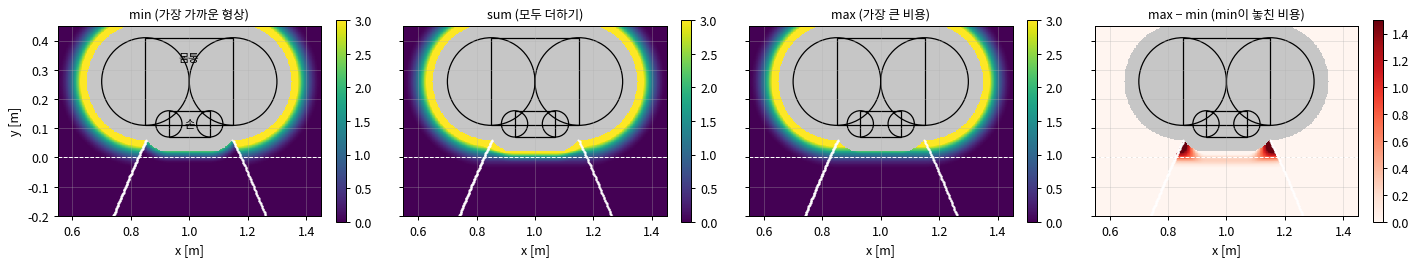

In [3]:
xs, ys = np.linspace(0.55, 1.45, 361), np.linspace(-0.20, 0.45, 261)
X, Y = np.meshgrid(xs, ys)
PG = np.stack([X, Y], -1)
CG, GG = shape_costs(PG, SHAPES)
MAP = {m: combine_cost(PG, (0.0, 0.0), SHAPES, m) for m in MODES}
touch = (GG < 0).any(-1)
lab = np.argmin(GG, -1)
edge = np.zeros_like(touch)
edge[:, 1:] |= lab[:, 1:] != lab[:, :-1]
edge[1:, :] |= lab[1:, :] != lab[:-1, :]
edge &= ~touch

fig, axs = plt.subplots(1, 4, figsize=(19, 4.6), sharey=True)
panels = [('min (가장 가까운 형상)', MAP['min'], 'viridis', 3.0), ('sum (모두 더하기)', MAP['sum'], 'viridis', 3.0),
          ('max (가장 큰 비용)', MAP['max'], 'viridis', 3.0), ('max − min (min이 놓친 비용)', MAP['max'] - MAP['min'], 'Reds', 1.5)]
for ax, (title, V, cmap, vmax) in zip(axs, panels):
    im = ax.pcolormesh(X, Y, np.ma.masked_where(touch, V), cmap=cmap, vmin=0, vmax=vmax, shading='auto')
    ax.pcolormesh(X, Y, np.ma.masked_where(~touch, np.ones_like(V)), cmap='Greys', vmin=0, vmax=3, shading='auto')
    ax.plot(X[edge], Y[edge], '.', color='w', ms=1.2)
    for s in SHAPES:
        draw_capsule(ax, s, 'k', fill=False)
    ax.axhline(0, color='w', ls='--', lw=0.8)
    ax.set_aspect('equal'); ax.set_title(title, fontsize=10); ax.set_xlabel('x [m]')
    fig.colorbar(im, ax=ax, fraction=0.035)
axs[0].set_ylabel('y [m]')
axs[0].text(1.0, HAND['a'][1], '손', ha='center', va='center', fontsize=9); axs[0].text(1.0, 0.33, '몸통', ha='center', fontsize=9)
plt.show()

free = ~touch
hand_near = free & (lab == 0)
shadow = hand_near & (CG[..., 1] > CG[..., 0])
print('닿지 않는 곳 중 손이 가장 가까운 영역: 격자 점 %d개' % hand_near.sum())
print('  그중 몸통 비용 > 손 비용인 점(min이 더 큰 몸통 비용을 놓치는 점): %d개 (%.0f%%)' % (shadow.sum(), 100 * shadow.sum() / hand_near.sum()))
print('  max − min의 최댓값 %.3f, 위치 (%.3f, %.3f)' % ((MAP['max'] - MAP['min'])[free].max(), *PG[free][np.argmax((MAP['max'] - MAP['min'])[free])]))
print('sum − max의 최댓값 %.3f (두 형상 비용이 동시에 켜진 곳에서만 0이 아님)' % (MAP['sum'] - MAP['max'])[free].max())

**지도에서 보이는 것**
- **min에는 손 앞에 홈이 있다.** 두 흰 선 사이, 손 바로 앞의 띠가 어둡다. 이곳에서는 손이 가장 가까운 형상이다. 그런데 로봇이 손 η(0.042 m) 밖이거나 경계 근처라서 손 비용이 작다. 같은 곳이 몸통 η(0.10 m) 안이라 몸통 비용은 크지만, min은 그것을 쓰지 않는다.
- **max와 sum에는 홈이 없다.** 몸통 비용의 띠가 손 앞에서도 끊기지 않는다.
- 흰 선(가장 가까운 형상이 바뀌는 선)은 손 앞면 양쪽 모서리에서 아래로 비스듬히 뻗는다. 이 선 위에서는 손 간격과 몸통 간격이 같다.

**몸통 그림자**는 가벼운 손이 가장 가까운 형상이 되어, 바로 뒤 무거운 몸통의 더 큰 비용이 min에서 빠지는 현상이다. 16의 "몸통 그늘"(몸통이 가장 가까워 팔의 비용이 빠짐)과 방향만 반대이고 원인은 같다. 둘 다 가장 가까운 형상 하나만 보기 때문에 생긴다.
- 닿지 않는 곳 중 손이 가장 가까운 격자 점은 15646개다. 그중 23%(3545개)에서 몸통 비용이 손 비용보다 컸다.
- max − min은 최대 2.873이다. 위치는 (1.150, 0.055)로, 손 앞면 모서리와 흰 선이 만나는 근처다.
- sum − max는 최대 2.106이다. 두 형상의 비용이 동시에 켜진 곳에서만 차이가 난다.

**확인 문제 1-1 (계산).** 어떤 점에서 손 간격 0.02 m(η를 반올림해 0.042 m), 몸통 간격 0.06 m(η 0.10 m), w = 100이다. 손 비용, 몸통 비용, 그리고 min·sum·max는?

<details><summary>답</summary>

손: 100 × (0.042 − 0.02)² / (2 × 0.042) = **0.576**. 몸통: 100 × (0.10 − 0.06)² / 0.2 = **0.8**. 손이 더 가까우므로 min = **0.576**, sum = **1.376**, max = **0.8**. min은 더 큰 몸통 비용을 쓰지 않는다.
</details>

**확인 문제 1-2 (보기).** 형상마다 η가 모두 같다면, "가장 가까운 형상의 비용(min)"은 다음 중 무엇과 같은가? (a) sum (b) max (c) 같은 것이 없다

<details><summary>답</summary>

**(b) max.** η가 같으면 비용은 간격만의 함수이고, 간격이 작을수록 크다. 가장 가까운 형상의 비용이 곧 가장 큰 비용이다. 14~17(균일 η)에서는 min과 max가 같았다.
</details>

## 2. 연속성 — 가장 가까운 형상이 바뀌는 선에서

**이것이 답하는 질문:** 1절의 지도에서 min은 흰 점선을 경계로 색이 갈라졌다. 그 선을 가로지르면 비용 값이 뛰는가?

로봇의 직선 길(y = 0)은 손 앞을 지나며 흰 점선을 두 번 넘는다. 이 선 위에서 세 방식의 값을 1D로 그린다. 오른쪽 그림은 x = 1.0에서 길과 수직으로(아래 → 손 쪽) 올라가는 선이다.

**연속**은 선을 따라가며 값이 끊기지 않고 이어진다는 뜻이다. **꺾임**은 값은 이어지지만 기울기가 갑자기 바뀌는 것이다.

In [4]:
xl = np.linspace(0.6, 1.4, 16001)
PL = np.stack([xl, np.zeros_like(xl)], -1)
CL, GL = shape_costs(PL, SHAPES)
LINE = {m: combine_cost(PL, (0.0, 0.0), SHAPES, m) for m in MODES}
labl = np.argmin(GL, -1)
sw = np.where(np.diff(labl) != 0)[0]
print('길(y = 0) 위에서 가장 가까운 형상이 바뀌는 x:', ', '.join('%.4f' % xl[i] for i in sw))
for i in sw:
    print('\n x = %.4f: 손 간격 %.4f, 몸통 간격 %.4f, 손 비용 %.3f, 몸통 비용 %.3f' % (xl[i], GL[i, 0], GL[i, 1], CL[i, 0], CL[i, 1]))
    for m in MODES:
        print('   %-3s 왼쪽 %.3f → 오른쪽 %.3f (차이 %+.3f)' % (m, LINE[m][i], LINE[m][i + 1], LINE[m][i + 1] - LINE[m][i]))
print('\n격자 간격 %.0e m에서 이웃 점 사이 가장 큰 변화: min %.3f, sum %.4f, max %.4f'
      % (xl[1] - xl[0], *[np.abs(np.diff(LINE[m])).max() for m in MODES]))

# 같은 선에서 손 η도 몸통과 같게(0.10) 하면?
UNI = [capsule(HAND['a'], HAND['b'], HAND['r'], ETA_T, 'hand'), TORSO]
uni_min = combine_cost(PL, (0.0, 0.0), UNI, 'min')
print('손 η = 몸통 η = %.2f로 같게 하면: min의 이웃 점 사이 가장 큰 변화 %.4f' % (ETA_T, np.abs(np.diff(uni_min)).max()))

# x = 1.0 수직선: 손이 가장 가까운 영역 안에서 max의 꺾임
yv = np.linspace(-0.12, 0.06, 18001)
PV = np.stack([np.ones_like(yv), yv], -1)
CV, GV = shape_costs(PV, SHAPES)
VERT = {m: combine_cost(PV, (0.0, 0.0), SHAPES, m) for m in MODES}
print('\nx = 1.0 수직선(y −0.12 → 0.06)에서 가장 가까운 형상: 내내 %s' % ('손' if (np.argmin(GV, -1) == 0).all() else '바뀜'))
k = np.where(np.diff(np.sign(CV[:, 1] - CV[:, 0])) != 0)[0]
k = k[CV[k, 0] > 0][0]
dy = yv[1] - yv[0]
slope = lambda v, j: (v[j] - v[j - 1]) / dy
print('손 비용 = 몸통 비용이 되는 y = %.4f (비용 %.3f)' % (yv[k], CV[k, 0]))
for m in MODES:
    print('   %-3s 기울기 왼쪽 %.2f → 오른쪽 %.2f' % (m, slope(VERT[m], k - 5), slope(VERT[m], k + 6)))
print('그 아래(y < %.4f)에서는 몸통 비용이 더 크지만 min은 손 비용을 쓴다: y = −0.03에서 손 %.3f, 몸통 %.3f'
      % (yv[k], *CV[np.argmin(np.abs(yv + 0.03))]))

길(y = 0) 위에서 가장 가까운 형상이 바뀌는 x: 0.8241, 1.1758

 x = 0.8241: 손 간격 0.0613, 몸통 간격 0.0613, 손 비용 0.000, 몸통 비용 0.750
   min 왼쪽 0.750 → 오른쪽 0.000 (차이 -0.750)
   sum 왼쪽 0.750 → 오른쪽 0.750 (차이 +0.000)
   max 왼쪽 0.750 → 오른쪽 0.750 (차이 +0.000)

 x = 1.1758: 손 간격 0.0613, 몸통 간격 0.0613, 손 비용 0.000, 몸통 비용 0.750
   min 왼쪽 0.000 → 오른쪽 0.750 (차이 +0.750)
   sum 왼쪽 0.750 → 오른쪽 0.750 (차이 -0.000)
   max 왼쪽 0.750 → 오른쪽 0.750 (차이 -0.000)

격자 간격 5e-05 m에서 이웃 점 사이 가장 큰 변화: min 0.750, sum 0.0006, max 0.0004
손 η = 몸통 η = 0.10로 같게 하면: min의 이웃 점 사이 가장 큰 변화 0.0016

x = 1.0 수직선(y −0.12 → 0.06)에서 가장 가까운 형상: 내내 손
손 비용 = 몸통 비용이 되는 y = 0.0108 (비용 1.291)
   min 기울기 왼쪽 78.11 → 오른쪽 78.37
   sum 기울기 왼쪽 128.87 → 오른쪽 129.25
   max 기울기 왼쪽 50.77 → 오른쪽 78.37
그 아래(y < 0.0108)에서는 몸통 비용이 더 크지만 min은 손 비용을 쓴다: y = −0.03에서 손 0.000, 몸통 0.050


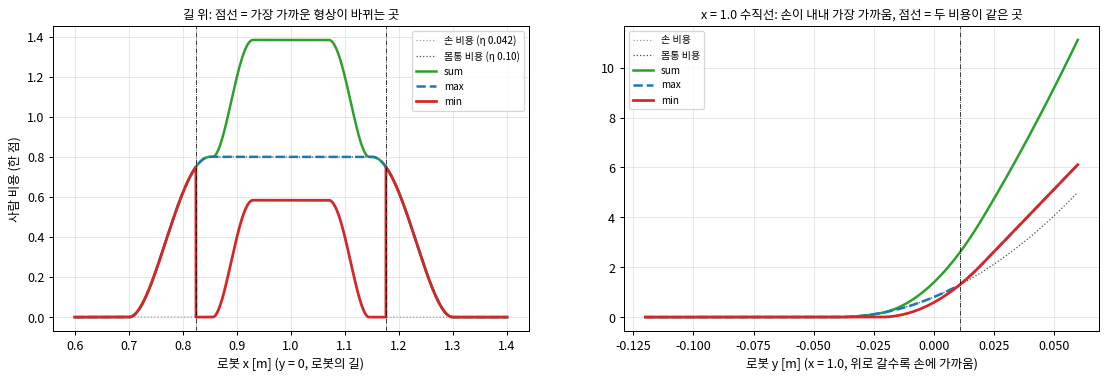

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axs[0]
ax.plot(xl, CL[:, 0], color='0.6', lw=1, ls=':', label='손 비용 (η %.3f)' % ETA_H)
ax.plot(xl, CL[:, 1], color='0.3', lw=1, ls=':', label='몸통 비용 (η %.2f)' % ETA_T)
for m, ls, lw in [('sum', '-', 2.0), ('max', '--', 2.0), ('min', '-', 2.2)]:
    ax.plot(xl, LINE[m], color=COL[m], ls=ls, lw=lw, label=m)
for i in sw:
    ax.axvline(xl[i], color='k', lw=0.6, ls='-.')
ax.set_xlabel('로봇 x [m] (y = 0, 로봇의 길)'); ax.set_ylabel('사람 비용 (한 점)'); ax.legend(fontsize=8)
ax.set_title('길 위: 점선 = 가장 가까운 형상이 바뀌는 곳', fontsize=10)
ax = axs[1]
ax.plot(yv, CV[:, 0], color='0.6', lw=1, ls=':', label='손 비용')
ax.plot(yv, CV[:, 1], color='0.3', lw=1, ls=':', label='몸통 비용')
for m, ls, lw in [('sum', '-', 2.0), ('max', '--', 2.0), ('min', '-', 2.2)]:
    ax.plot(yv, VERT[m], color=COL[m], ls=ls, lw=lw, label=m)
ax.axvline(yv[k], color='k', lw=0.6, ls='-.')
ax.set_xlabel('로봇 y [m] (x = 1.0, 위로 갈수록 손에 가까움)'); ax.legend(fontsize=8)
ax.set_title('x = 1.0 수직선: 손이 내내 가장 가까움, 점선 = 두 비용이 같은 곳', fontsize=10)
plt.show()

**길(y = 0) 위 (왼쪽 그림)**
- 가장 가까운 형상은 x = 0.8241과 1.1758에서 바뀐다. 두 곳 모두 손 간격과 몸통 간격이 0.0613 m로 같다.
- 이 간격은 손 η(0.042 m) 밖이라 손 비용이 0이고, 몸통 비용은 0.750이다.
- **min은 0.750 → 0으로 떨어졌다가 0 → 0.750으로 다시 뛴다.** 두 경계 사이에서는 손 비용만 써서 최대 0.583이다(x 0.93~1.07). 같은 구간에서 max는 몸통 비용 0.800이다. 길 위에서 보이는 몸통 그림자다.
- sum과 max는 5 × 10⁻⁵ m 떨어진 이웃 점 사이에서 0.0006, 0.0004 이하로만 바뀌었다. 끊기지 않는다.

**왜 이런가 — "연속 함수들의 최댓값은 연속"**
- **max**는 비용으로 고른다. 고르는 형상이 바뀌는 곳은 두 비용이 같은 곳이다. 그러니 바뀌는 순간에도 값이 뛰지 않는다. sum은 연속 함수의 합이라 당연히 이어진다.
- **min**은 간격으로 고른다. 고르는 형상이 바뀌는 곳에서 간격은 같다. 그러나 η가 달라서 두 비용이 다르다(여기서는 0과 0.750). 그 차이만큼 값이 뛴다.
- 확인: 손 η를 몸통과 같은 0.10 m로 바꾸면 min의 이웃 점 사이 최대 변화가 0.0016으로 줄어 이어진다(확인 문제 1-2).

**x = 1.0 수직선 (오른쪽 그림)**
- 이 선에서는 손이 내내 가장 가깝다.
- y = 0.0108(비용 1.291)에서 손 비용과 몸통 비용이 같아진다.
  - **max**: 이곳에서 기울기가 50.77 → 78.37로 바뀐다. 값은 이어지지만 **꺾인다**. 그래서 max는 연속이지만 매끄럽지는 않다.
  - **sum**: 128.87 → 129.25로 매끄럽다.
  - **min**: 78.11 → 78.37로 매끄럽다.
- 그 아래(y < 0.0108)는 몸통 비용이 더 큰 구간이다. min은 손 비용을 쓴다. 예를 들어 y = −0.03에서 손 비용은 0, 몸통 비용은 0.050이다.

**확인 문제 2-1 (보기).** 형상 비용 $c_1, c_2$가 모두 연속일 때, 항상 연속인 것을 모두 고르면? (a) $\max(c_1, c_2)$ (b) $c_1 + c_2$ (c) 간격이 더 작은 형상의 비용

<details><summary>답</summary>

**(a), (b).** (a)는 두 값이 같아지는 곳에서만 고르는 것이 바뀌고, 그곳에서 두 값이 같으므로 끊기지 않는다. (b)는 연속 함수의 합이다. (c)는 간격으로 고르므로, 고르는 것이 바뀌는 곳(간격이 같은 곳)에서 두 비용이 다를 수 있다(η가 다르면 다르다).
</details>

**확인 문제 2-2 (계산).** 가장 가까운 형상이 바뀌는 점에서 두 간격이 모두 0.03 m다. 손 η 0.042 m, 몸통 η 0.10 m, w = 100이면 min 비용은 얼마나 뛰는가?

<details><summary>답</summary>

손: 100 × 0.012² / 0.084 = 0.171. 몸통: 100 × 0.07² / 0.2 = 2.45. **약 2.28** 뛴다(몸통 쪽 2.45 ↔ 손 쪽 0.171).
</details>

## 3. 중복 계산 — 같은 몸통을 캡슐 여러 개로 나누면

**이것이 답하는 질문:** 2절에서 sum은 연속이었다. 하지만 sum에는 다른 문제가 있을 수 있다. 몸을 형상 몇 개로 나타낼지는 모델을 만드는 사람이 정한다. 같은 몸을 더 잘게 나누면 비용이 바뀌는가?

**중복 계산**은 같은 몸의 같은 부분이 형상 여러 개에 들어가 비용이 여러 번 더해지는 것이다. 몸통 캡슐 하나를, 서로 조금씩 겹치는 같은 반지름의 캡슐 2개, 3개로 나눈다. 나눈 캡슐들을 합친 모양은 원래 몸통과 똑같다. η도 모두 0.10 m로 같다. 손은 그대로 둔다.

In [6]:
def split_torso(n, overlap=0.03):
    # 몸통 중심선 [0.85, 1.15]를 n등분하고 양쪽으로 overlap씩 늘린다. 합친 모양은 원래 몸통과 같다
    xe = np.linspace(TORSO['a'][0], TORSO['b'][0], n + 1)
    y = TORSO['a'][1]
    return [capsule((max(xe[0], xe[i] - overlap), y), (min(xe[-1], xe[i + 1] + overlap), y), TORSO['r'], ETA_T, 'torso%d' % i) for i in range(n)]

SPLIT = {n: [HAND] + split_torso(n) for n in (1, 2, 3)}
for n in (2, 3):
    print('몸통 %d개: 각 캡슐 중심선 x = %s' % (n, ', '.join('%.2f~%.2f' % (s['a'][0], s['b'][0]) for s in SPLIT[n][1:])))
    print('   몸통 간격(나눈 캡슐 중 최소) − 원래 몸통 간격의 최대 차이(평면 격자): %.1e m' % np.abs(shape_gaps(PG, SPLIT[n])[..., 1:].min(-1) - GG[..., 1]).max())

print('\n평면 격자(닿지 않는 곳)에서 몸통 1개 대비 최대 변화:')
for n in (2, 3):
    d = {m: np.abs(combine_cost(PG, (0.0, 0.0), SPLIT[n], m) - MAP[m])[free].max() for m in MODES}
    print('   몸통 %d개: min %.1e, max %.1e, sum %.3f' % (n, d['min'], d['max'], d['sum']))

print('\n길(y = 0) 위의 값')
print('%-8s | %-26s | %-26s | %-26s' % ('x [m]', 'min (몸통 1 / 2 / 3개)', 'sum (몸통 1 / 2 / 3개)', 'max (몸통 1 / 2 / 3개)'))
for x in (0.80, 0.90, 1.00, 1.10):
    P = np.array([x, 0.0])
    v = {m: [float(combine_cost(P, (0.0, 0.0), SPLIT[n], m)) for n in (1, 2, 3)] for m in MODES}
    print('%-8.2f | %-26s | %-26s | %-26s' % (x, *[' / '.join('%.3f' % a for a in v[m]) for m in MODES]))

몸통 2개: 각 캡슐 중심선 x = 0.85~1.03, 0.97~1.15
   몸통 간격(나눈 캡슐 중 최소) − 원래 몸통 간격의 최대 차이(평면 격자): 0.0e+00 m
몸통 3개: 각 캡슐 중심선 x = 0.85~0.98, 0.92~1.08, 1.02~1.15
   몸통 간격(나눈 캡슐 중 최소) − 원래 몸통 간격의 최대 차이(평면 격자): 0.0e+00 m

평면 격자(닿지 않는 곳)에서 몸통 1개 대비 최대 변화:
   몸통 2개: min 0.0e+00, max 0.0e+00, sum 2.315
   몸통 3개: min 0.0e+00, max 0.0e+00, sum 4.718

길(y = 0) 위의 값
x [m]    | min (몸통 1 / 2 / 3개)        | sum (몸통 1 / 2 / 3개)        | max (몸통 1 / 2 / 3개)       
0.80     | 0.621 / 0.621 / 0.621      | 0.621 / 0.621 / 0.714      | 0.621 / 0.621 / 0.621     
0.90     | 0.399 / 0.399 / 0.399      | 1.199 / 1.671 / 2.061      | 0.800 / 0.800 / 0.800     
1.00     | 0.583 / 0.583 / 0.583      | 1.383 / 2.183 / 2.923      | 0.800 / 0.800 / 0.800     
1.10     | 0.399 / 0.399 / 0.399      | 1.199 / 1.671 / 2.061      | 0.800 / 0.800 / 0.800     


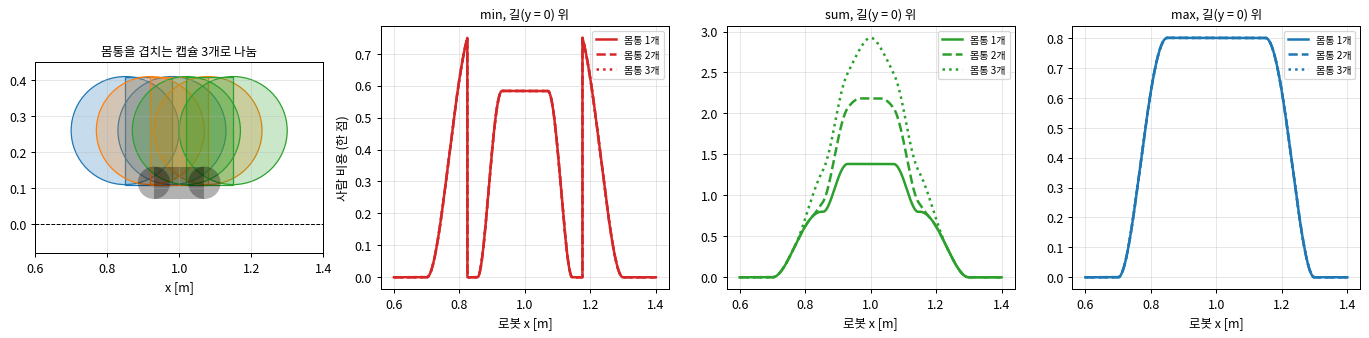

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(19, 3.8))
ax = axs[0]
for s, c in zip(SPLIT[3][1:], ['C0', 'C1', 'C2']):
    draw_capsule(ax, s, c, alpha=0.25)
    draw_capsule(ax, s, c, fill=False)
draw_capsule(ax, HAND, 'k', alpha=0.3)
ax.axhline(0, color='k', ls='--', lw=0.8); ax.set_xlim(0.6, 1.4); ax.set_ylim(-0.08, 0.45); ax.set_aspect('equal')
ax.set_title('몸통을 겹치는 캡슐 3개로 나눔', fontsize=10); ax.set_xlabel('x [m]')
for ax, m in zip(axs[1:], MODES):
    for n, ls in [(1, '-'), (2, '--'), (3, ':')]:
        ax.plot(xl, combine_cost(PL, (0.0, 0.0), SPLIT[n], m), color=COL[m], ls=ls, lw=2, label='몸통 %d개' % n)
    ax.set_title('%s, 길(y = 0) 위' % m, fontsize=10); ax.set_xlabel('로봇 x [m]'); ax.legend(fontsize=8)
axs[1].set_ylabel('사람 비용 (한 점)')
plt.show()

**나눠도 같은 몸이다.** 나눈 캡슐 중 가장 가까운 것과의 간격은 원래 몸통과의 간격과 평면 전체에서 같았다(차이 0.0 m).

**min과 max는 그대로다.** 평면 격자에서 몸통 1개 대비 변화가 0이다. 나눈 캡슐들은 η가 같고 가장 가까운 것의 간격도 같아서, 가장 가까운 것의 비용과 가장 큰 비용이 그대로이기 때문이다.

**sum만 커졌다.**
- 평면 격자에서 최대 변화: 몸통 2개 +2.315, 3개 +4.718
- 길 위 (1.0, 0): 1.383 → 2.183 → 2.923. 몸통 몫이 0.800 → 1.600 → 2.340으로 나눈 개수에 거의 비례해 늘었다.
- x = 0.80처럼 나눈 캡슐 하나만 η 안에 들어오는 곳에서는 거의 그대로다(0.621 / 0.621 / 0.714).

sum의 값은 몸 자체가 아니라 **모델을 만드는 사람이 몸을 몇 조각으로 나눴는지**에 따라 달라진다. 이것이 중복 계산이다.

**확인 문제 3-1 (계산).** 몸통을 겹치는 캡슐 2개로 나눴더니 어떤 점에서 두 캡슐과의 간격이 모두 0.06 m(η 0.10 m, w = 100)다. 손 비용은 0이다. 이 점에서 min, sum, max는? 나누기 전에는?

<details><summary>답</summary>

캡슐 하나의 비용은 100 × 0.04² / 0.2 = 0.8. 나눈 뒤: min **0.8**, sum **1.6**, max **0.8**. 나누기 전: 셋 다 **0.8**. sum만 두 배가 된다.
</details>

## 4. MPPI 회피 — 세 방식으로 실제로 지나가 보기

**이것이 답하는 질문:** 1~3절의 비용 차이(min의 몸통 그림자와 뛰는 값, sum의 중복 계산)가 로봇의 실제 회피를 바꾸는가?

14~17과 같은 MPPI(`run_mpc_opts`, 기본 설정)로 (0, 0) → (2.0, 0)을 간다. 사람 비용만 세 방식으로 바꾼다. seed 8개이고, 모든 방식이 같은 seed 8개를 쓴다. 3절의 몸통 나누기도 함께 돌린다. max는 나눠도 비용이 같으므로 궤적도 같아야 한다.

**지표**
- 손과 몸통 각각의 최소 간격, 그리고 같은 seed의 max와의 차이
- 실행한 경로 위에서 가장 가까운 형상이 바뀐 스텝 ±2스텝("경계 근처")과 사람 옆을 지나는 구간(x 0.75~1.25 m)의 ESS와 명령 변화량 |u_t − u_{t−1}|
- 후보 경로 단위: 마지막 반복에서 (i) 몸통 그림자(손이 가장 가깝고 몸통 비용이 더 큰 점)를 지나는 후보의 비율, (ii) 가장 가까운 형상이 바뀌는 곳을 비용이 켜진 채로 넘는 후보의 비율

In [8]:
CASES = [('min', 1), ('sum', 1), ('max', 1), ('sum', 2), ('sum', 3), ('max', 3), ('min', 3)]
SEEDS = range(8)

def recording_cost(mode, shapes, log):
    # combine_cost를 그대로 쓰되, 부를 때마다 후보 경로 통계를 log에 남긴다
    def f(Pf, offsets):
        c, g = shape_costs(Pf, shapes, offsets)
        out = combine_cost(Pf, offsets, shapes, mode)
        g_h, g_t = g[..., 0], g[..., 1:].min(-1)
        c_t = c[..., 1:].max(-1)
        shadow = ((g_h < g_t) & (c_t > c[..., 0])).any(-1)
        lab = g_h < g_t
        cross = ((lab[..., 1:] != lab[..., :-1]) & ((c.max(-1)[..., 1:] > 0) | (c.max(-1)[..., :-1] > 0))).any(-1)
        log.append((float(shadow.mean()), float(cross.mean())))
        return out
    return f

t0 = time.time()
R4 = {}
for mode, n in CASES:
    R4[(mode, n)] = []
    for s in SEEDS:
        log = []
        r = run_mpc_opts(recording_cost(mode, SPLIT[n], log), seed=s)
        assert len(log) == S.STEPS * S.N_ITERS
        r['cand'] = np.array(log)[S.N_ITERS - 1::S.N_ITERS]       # 스텝마다 마지막 반복
        R4[(mode, n)].append(r)
print('실행 시간 %.0f s (실행 %d개)' % (time.time() - t0, len(CASES) * len(SEEDS)))

def metrics(r, shapes):
    tr = r['traj'][1:]
    G = shape_gaps(tr, shapes)
    g_h, g_t = G[:, 0], G[:, 1:].min(-1)
    sw = np.where(np.diff((g_h < g_t).astype(int)) != 0)[0]
    near = np.zeros(len(tr), bool)
    for i in sw:
        near[max(0, i - 2):i + 4] = True
    du = np.r_[0.0, np.linalg.norm(np.diff(r['us'], axis=0), axis=1)]
    pas = (tr[:, 0] > 0.75) & (tr[:, 0] < 1.25)
    return dict(h=g_h.min(), t=g_t.min(), n_sw=len(sw), in_eta=int(((g_h < ETA_H) | (g_t < ETA_T)).sum()),
                ess_b=r['ess'][near].mean(), du_b=du[near].mean(), ess_p=r['ess'][pas].mean(), du_p=du[pas].mean(),
                shadow_p=r['cand'][pas, 0].mean(), cross_p=r['cand'][pas, 1].mean(), shadow_a=r['cand'][:10, 0].mean(), cross_a=r['cand'][:10, 1].mean(),
                ymin=r['traj'][:, 1].min())

M4 = {k: [metrics(r, SPLIT[k[1]]) for r in v] for k, v in R4.items()}
arr = lambda k, q: np.array([m[q] for m in M4[k]])
name = lambda k: '%s' % k[0] if k[1] == 1 else '%s (몸통 %d개)' % k
print('\n%-16s | %-13s | %-13s | %-6s | %-6s | %-15s | %-15s | %-16s | %s' % ('방식', '손 최소 간격', '몸통 최소 간격', '경로 전환', 'η 안 스텝', '경계 근처 ESS·명령', '통과 구간 ESS·명령', '후보 그림자: 접근 / 통과', '후보 경계 넘음: 접근 / 통과'))
for k in R4:
    print('%-16s | %.3f~%.3f   | %.3f~%.3f   | %-6s | %-6d | %5.1f · %.2f     | %5.1f · %.2f     | %.2f / %.2f      | %.2f / %.2f'
          % (name(k), arr(k, 'h').min(), arr(k, 'h').max(), arr(k, 't').min(), arr(k, 't').max(), '/'.join(str(v) for v in sorted(set(arr(k, 'n_sw')))),
             arr(k, 'in_eta').sum(), arr(k, 'ess_b').mean(), arr(k, 'du_b').mean(), arr(k, 'ess_p').mean(), arr(k, 'du_p').mean(),
             arr(k, 'shadow_a').mean(), arr(k, 'shadow_p').mean(), arr(k, 'cross_a').mean(), arr(k, 'cross_p').mean()))
print('(경로 전환: 실행한 경로에서 가장 가까운 형상이 바뀐 횟수. η 안 스텝: 실행한 경로가 손 η 또는 몸통 η 안에 들어간 스텝 수, seed 8개 합.')
print(' 후보 비율은 마지막 반복의 후보 400개 중 비율, 접근 = 0~0.5 s, 통과 = 로봇 x 0.75~1.25 m)')

print('\n같은 seed끼리 max(몸통 1개)와의 차이 [cm]: 양수 = max보다 멀리 지나감')
for k in [('min', 1), ('sum', 1), ('sum', 2), ('sum', 3), ('max', 3), ('min', 3)]:
    out = []
    for q, lbl in [('h', '손'), ('t', '몸통')]:
        d = (arr(k, q) - arr(('max', 1), q)) * 100
        out.append('%s %d / 8 양수, %+.2f~%+.2f (평균 %+.2f)' % (lbl, (d > 0).sum(), d.min(), d.max(), d.mean()))
    print('%-16s | %s' % (name(k), ' | '.join(out)))
for k in [('max', 3), ('min', 3)]:
    base = ('max', 1) if k[0] == 'max' else ('min', 1)
    print('%s와 %s의 궤적 최대 차이: %.1e m' % (name(k), name(base), max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(R4[k], R4[base]))))

실행 시간 175 s (실행 56개)

방식               | 손 최소 간격       | 몸통 최소 간격      | 경로 전환  | η 안 스텝 | 경계 근처 ESS·명령    | 통과 구간 ESS·명령    | 후보 그림자: 접근 / 통과  | 후보 경계 넘음: 접근 / 통과
min              | 0.076~0.111   | 0.111~0.145   | 2      | 0      |  55.6 · 1.25     |  55.3 · 1.51     | 0.29 / 0.03      | 0.32 / 0.04
sum              | 0.087~0.117   | 0.123~0.150   | 2      | 0      |  55.6 · 1.26     |  55.3 · 1.50     | 0.27 / 0.01      | 0.30 / 0.02
max              | 0.085~0.117   | 0.121~0.150   | 2      | 0      |  55.6 · 1.26     |  55.3 · 1.50     | 0.27 / 0.01      | 0.30 / 0.02
sum (몸통 2개)      | 0.089~0.118   | 0.124~0.151   | 2      | 0      |  55.6 · 1.26     |  55.3 · 1.50     | 0.27 / 0.01      | 0.29 / 0.02
sum (몸통 3개)      | 0.090~0.119   | 0.125~0.152   | 2      | 0      |  55.6 · 1.26     |  55.3 · 1.50     | 0.27 / 0.01      | 0.29 / 0.02
max (몸통 3개)      | 0.085~0.117   | 0.121~0.150   | 2      | 0      |  55.6 · 1.26     |  55.3 · 1.50     | 0.27 / 0.01      | 0.30 / 0.02
min (몸통 

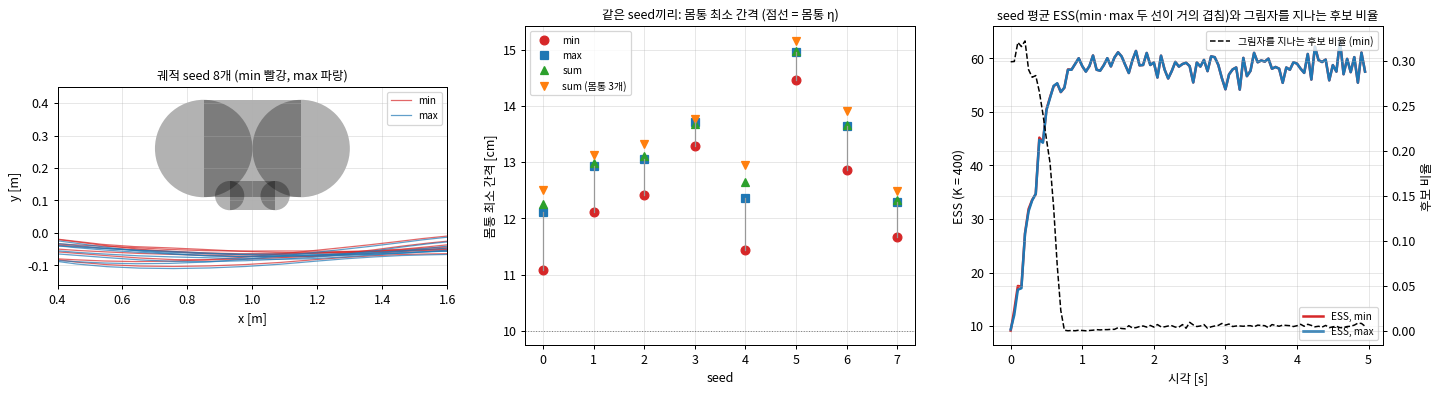

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(19, 4.6))
ax = axs[0]
for s in SHAPES:
    draw_capsule(ax, s, 'k', alpha=0.3)
for mode in ('min', 'max'):
    for i, r in enumerate(R4[(mode, 1)]):
        ax.plot(r['traj'][:, 0], r['traj'][:, 1], color=COL[mode], lw=1, alpha=0.7, label=mode if i == 0 else None)
ax.set_xlim(0.4, 1.6); ax.set_ylim(-0.16, 0.45); ax.set_aspect('equal'); ax.legend(fontsize=8)
ax.set_title('궤적 seed 8개 (min 빨강, max 파랑)', fontsize=10); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')

ax = axs[1]
for k, mk in [(('min', 1), 'o'), (('max', 1), 's'), (('sum', 1), '^'), (('sum', 3), 'v')]:
    ax.plot(list(SEEDS), arr(k, 't') * 100, mk, color=COL[k[0]] if k[1] == 1 else 'C1', ms=7, label=name(k))
for s in SEEDS:
    ax.plot([s, s], [arr(('min', 1), 't')[s] * 100, arr(('max', 1), 't')[s] * 100], color='0.6', lw=1)
ax.axhline(ETA_T * 100, color='gray', ls=':', lw=0.8)
ax.set_xlabel('seed'); ax.set_ylabel('몸통 최소 간격 [cm]'); ax.legend(fontsize=8)
ax.set_title('같은 seed끼리: 몸통 최소 간격 (점선 = 몸통 η)', fontsize=10)

ax = axs[2]
t = np.arange(S.STEPS) * S.DT
for mode in ('min', 'max'):
    ax.plot(t, np.mean([r['ess'] for r in R4[(mode, 1)]], 0), color=COL[mode], lw=2, label='ESS, %s' % mode)
ax2 = ax.twinx()
ax2.plot(t, np.mean([r['cand'][:, 0] for r in R4[('min', 1)]], 0), color='k', ls='--', lw=1.2, label='그림자를 지나는 후보 비율 (min)')
ax2.set_ylabel('후보 비율')
ax.set_xlabel('시각 [s]'); ax.set_ylabel('ESS (K = 400)'); ax.legend(fontsize=8, loc='lower right'); ax2.legend(fontsize=8, loc='upper right')
ax.set_title('seed 평균 ESS(min·max 두 선이 거의 겹침)와 그림자를 지나는 후보 비율', fontsize=10)
plt.show()

**실행한 경로는 어느 η 안에도 들어가지 않았다.** η 안에 든 스텝이 모든 방식에서 0이었다. 손 최소 간격은 0.076 m 이상(η 0.042), 몸통은 0.111 m 이상(η 0.10)이다. 로봇은 사람 아래쪽(y < 0)으로 지나갔다. η보다 멀리 지나가는 것은 17에서 본 잡음 편향과 같은 현상이다.

**min은 max보다 가깝게 지나갔다.**
- 같은 seed끼리 비교하면 8 / 8에서 가까웠다. 손 간격은 −0.46~−1.00 cm(평균 −0.73), 몸통 간격은 −0.42~−1.03 cm(평균 −0.72) 차이다.
- seed 범위는 겹친다(몸통: min 0.111~0.145, max 0.121~0.150 m). 17에서처럼 차이가 seed 간 흩어짐보다 작아, 같은 seed끼리 비교해야 보인다.

**sum은 max와 거의 같고, 몸통을 나누면 조금 더 멀어졌다.**
- sum(몸통 1개): +0.05 / +0.07 cm(7 / 8 양수)
- sum(몸통 2개): +0.17 / +0.18 cm(8 / 8)
- sum(몸통 3개): +0.26 / +0.27 cm(8 / 8)
- 중복 계산이 회피를 바꾸는 방향은 나왔다. 크기는 이 장면에서 0.3 cm 미만이었다.
- max와 min은 몸통을 3개로 나눠도 궤적이 완전히 같았다(차이 0.0 m).

**ESS와 명령 변화량은 방식에 따라 달라지지 않았다.**
- 경계 근처: 모든 방식에서 ESS 55.6, 명령 변화량 1.25~1.26 m/s²
- 사람 옆을 지나는 구간: ESS 55.3, 명령 변화량 1.50~1.51 m/s²
- 오른쪽 그림에서도 min과 max의 ESS 선이 거의 겹친다.

**비용이 뛰는 곳을 지난 것은 후보 경로였다.** 다가가는 동안(0~0.5 s)에는 몸통 그림자를 지나는 후보가 27~29%였다. 비용이 켜진 채 경계를 넘는 후보도 29~32%였다. 사람 옆을 지날 때는 둘 다 1~4%로 줄었다.
- 후보의 약 30%가 뛰는 비용을 겪었는데도 ESS와 명령 변화량이 같았던 이유는 4c에서, min이 0.7 cm 가까이 지나간 이유는 4d에서 후보 단위로 확인한다.
- 실제 경로가 η 안을 지나는 경우는 4b에서 따로 시험한다.

**확인 문제 4-1 (보기).** 이 절에서 min과 max의 몸통 최소 간격 범위가 서로 겹쳤는데도 "min이 더 가깝게 지나간다"고 말할 수 있는 근거는? (a) 평균만 비교했다 (b) 같은 seed끼리 짝지은 차이가 모두 같은 방향이었다 (c) 범위가 겹치지 않았다

<details><summary>답</summary>

**(b)**. 같은 seed끼리 짝지으면 min이 max보다 손 간격 0.46~1.00 cm, 몸통 간격 0.42~1.03 cm 작았다(8 / 8). 몸통 간격의 범위는 min 0.111~0.145 m, max 0.121~0.150 m로 겹쳤다.
</details>

**확인 문제 4-2 (보기).** 이 장면에서 min의 비용이 뛰는 곳이 실행한 명령의 떨림을 키우지 않은 이유로 이 노트가 확인한 것은? (a) 실행한 경로가 손·몸통 η 안에 들어가지 않아, 비용이 뛰는 곳을 지난 것은 후보 경로뿐이었다 (b) K가 너무 커서 (c) min은 연속이라서

<details><summary>답</summary>

**(a)**. 모든 방식에서 실행한 경로가 η 안에 든 스텝이 0이었다. 비용이 켜진 채 경계를 넘은 것은 후보(다가가는 동안 29~32%)뿐이었고, ESS(55.6)와 명령 변화량(1.25~1.26)은 방식에 따라 달라지지 않았다. (b)는 이 노트에서 확인하지 않았고, (c)는 틀렸다(min은 경계에서 뛴다).
</details>

## 4b. 실제 경로가 η 안을 지나면 — 가설 4 다시 시험

**이것이 답하는 질문:** 4절에서는 실제 경로가 η 밖으로만 지나가서, "min의 비용이 뛰는 곳에서 ESS가 줄고 명령이 흔들린다"(가설 4)를 실제 경로로는 시험하지 못했다. 경로가 손·몸통 η 안을 지나며 비용이 뛰는 곳을 실제로 넘으면 결과가 달라지는가?

장면(손, 몸통, η, w)은 그대로 두고 한 가지만 바꾼 변형을 찾는다. 먼저 두 가지를 시도한다(seed 8개).
- **σ를 0.5로 줄이기:** 17에서 잡음 편향이 작았던 값이다. 편향 때문에 η 밖으로 지나간 것이라면 η 안으로 들어올 것이다.
- **목표를 손 앞 (1.0, 0)으로 옮기기:** 목표 자체가 손 η(간격 0.020 m)와 몸통 η(0.060 m) 안에 있다.

In [10]:
def in_eta(tr, shapes=SHAPES):
    G = shape_gaps(tr, shapes)
    return (G[:, 0] < ETA_H) | (G[:, 1:].min(-1) < ETA_T)

t0 = time.time()
print('%-26s | %-4s | %-14s | %-13s | %-13s | %s' % ('시도', '방식', 'η 안 스텝 비율', '손 최소 간격', '몸통 최소 간격', '마지막 위치 (seed 평균)'))
for lbl, kw in [('σ = 0.5', dict(sigma=0.5)), ('목표 (1.0, 0)', dict(goal=(1.0, 0.0)))]:
    for mode in MODES:
        rs = [run_mpc_opts(partial(combine_cost, shapes=SHAPES, mode=mode), seed=s, **kw) for s in range(8)]
        G = [shape_gaps(r['traj'][1:], SHAPES) for r in rs]
        print('%-26s | %-4s | %-14.3f | %.3f~%.3f   | %.3f~%.3f   | (%.3f, %.3f)' % (lbl, mode, np.mean([in_eta(r['traj'][1:]).mean() for r in rs]),
              min(g[:, 0].min() for g in G), max(g[:, 0].min() for g in G), min(g[:, 1].min() for g in G), max(g[:, 1].min() for g in G),
              *np.mean([r['traj'][-1] for r in rs], 0)))
print('실행 시간 %.0f s' % (time.time() - t0))

시도                         | 방식   | η 안 스텝 비율      | 손 최소 간격       | 몸통 최소 간격      | 마지막 위치 (seed 평균)
σ = 0.5                    | min  | 0.000          | 0.070~0.086   | 0.108~0.122   | (2.004, 0.001)
σ = 0.5                    | sum  | 0.000          | 0.078~0.093   | 0.116~0.128   | (2.004, 0.001)
σ = 0.5                    | max  | 0.000          | 0.078~0.093   | 0.116~0.128   | (2.004, 0.001)
목표 (1.0, 0)                | min  | 0.000          | 0.084~0.101   | 0.124~0.141   | (0.996, -0.093)
목표 (1.0, 0)                | sum  | 0.000          | 0.090~0.108   | 0.123~0.146   | (0.992, -0.102)
목표 (1.0, 0)                | max  | 0.000          | 0.092~0.108   | 0.124~0.148   | (0.990, -0.103)
실행 시간 67 s


**두 시도 모두 실제 경로가 η 안에 한 스텝도 들어가지 않았다**(η 안 스텝 비율 0.000).
- **σ = 0.5:** 손 최소 간격은 0.070~0.093 m(η 0.042), 몸통은 0.108~0.128 m(η 0.10)였다. 4절(σ = 2)보다 조금 가깝고 범위가 좁아졌지만, 여전히 η 밖이다.
- **목표 (1.0, 0):** 로봇은 목표까지 가지 않았다. 목표보다 약 9~10 cm 아래(마지막 위치 y −0.093~−0.103 m)에 멈췄고, 손 간격은 0.084 m 이상이었다.
- (해석) 2D에서는 옆(−y)으로 몇 cm 물러날 때 늘어나는 목표 비용이 η 안에 들어갈 때의 사람 비용(w = 100)보다 훨씬 작다. 그래서 σ를 줄이거나 목표를 옮겨도 로봇은 η 밖을 택했다.

**바꾼 값: 로봇을 길(y = 0) 위에서만 움직이게 한다.** `run_mpc_opts(line=True)`, 즉 15의 1D 실행과 같이 y 방향 탐색 폭을 0으로 둔다. 장면, w, σ = 2, β = 1, K = 400, 목표 (2.0, 0)은 그대로다. 이 "레일" 위에서는 비켜 갈 수 없으므로, 로봇은 2절에서 본 몸통 η 안의 경계 두 곳(x = 0.824, 1.176, 뜀 0.750)을 반드시 넘는다.

세 방식 × seed 16개. 먼저 실제 경로가 η 안에 들어간 스텝 비율을 보고, 경계를 넘는 스텝 ±2스텝과 η 안 스텝에서 ESS와 명령 변화량 |u_t − u_{t−1}|을 비교한다.

In [11]:
SEEDS16 = range(16)

def rail_metrics(r):
    tr = r['traj'][1:]
    G = shape_gaps(tr, SHAPES)
    g_h, g_t = G[:, 0], G[:, 1]
    ine = in_eta(tr)
    sw = np.where(np.diff((g_h < g_t).astype(int)) != 0)[0]
    c, _ = shape_costs(tr, SHAPES)
    near = np.zeros(len(tr), bool)
    for i in sw:
        near[max(0, i - 2):i + 4] = True
    du = np.r_[0.0, np.abs(np.diff(r['us'][:, 0]))]
    return dict(ine=ine.mean(), n_in=ine.sum(), n_sw=len(sw), jump=max(abs(c[i, 1] - c[i, 0]) for i in sw) if len(sw) else 0.0,
                ess_b=r['ess'][near].mean(), du_b=du[near].mean(), ess_in=r['ess'][ine].mean(), du_in=du[ine].mean(), x_end=r['traj'][-1, 0])

t0 = time.time()
RAIL = {m: [run_mpc_opts(partial(combine_cost, shapes=SHAPES, mode=m), seed=s, line=True) for s in SEEDS16] for m in MODES}
MR = {m: [rail_metrics(r) for r in RAIL[m]] for m in MODES}
print('실행 시간 %.0f s\n' % (time.time() - t0))
ar = lambda m, q: np.array([x[q] for x in MR[m]])
print('%-4s | %-14s | %-11s | %-8s | %-20s | %-20s | %-20s | %s' % ('방식', 'η 안 스텝 비율', 'η 안 스텝 수', '경계 통과', '통과 스텝의 |몸통−손| 비용', '경계 ±2스텝 ESS·명령', 'η 안 스텝 ESS·명령', '마지막 x'))
for m in MODES:
    print('%-4s | %-14.3f | %d~%-9d | %-8s | %.3f~%.3f          | %5.1f · %.2f         | %5.1f · %.2f         | %.2f~%.2f'
          % (m, ar(m, 'ine').mean(), ar(m, 'n_in').min(), ar(m, 'n_in').max(), '/'.join(str(v) for v in sorted(set(ar(m, 'n_sw')))),
             ar(m, 'jump').min(), ar(m, 'jump').max(), ar(m, 'ess_b').mean(), ar(m, 'du_b').mean(), ar(m, 'ess_in').mean(), ar(m, 'du_in').mean(),
             ar(m, 'x_end').min(), ar(m, 'x_end').max()))
print('\n같은 seed끼리 max와의 차이 (양수 개수 / 16, 범위, 평균)')
for m in ('min', 'sum'):
    for q, lbl in [('ess_b', '경계 ±2 ESS'), ('du_b', '경계 ±2 명령 변화'), ('ess_in', 'η 안 ESS'), ('du_in', 'η 안 명령 변화')]:
        d = ar(m, q) - ar('max', q)
        print('  %-3s %-16s: %2d / 16, %+.2f~%+.2f, 평균 %+.2f' % (m, lbl, (d > 0).sum(), d.min(), d.max(), d.mean()))

실행 시간 69 s

방식   | η 안 스텝 비율      | η 안 스텝 수    | 경계 통과    | 통과 스텝의 |몸통−손| 비용     | 경계 ±2스텝 ESS·명령       | η 안 스텝 ESS·명령        | 마지막 x
min  | 0.060          | 6~6         | 2        | 0.266~0.783          | 140.9 · 0.61         | 142.8 · 0.79         | 1.98~2.03
sum  | 0.050          | 5~5         | 2        | 0.407~0.614          | 129.9 · 0.68         | 132.4 · 1.12         | 1.98~2.03
max  | 0.050          | 5~5         | 2        | 0.310~0.529          | 135.6 · 0.66         | 138.3 · 1.06         | 1.98~2.03

같은 seed끼리 max와의 차이 (양수 개수 / 16, 범위, 평균)
  min 경계 ±2 ESS       : 16 / 16, +2.53~+8.13, 평균 +5.29
  min 경계 ±2 명령 변화     :  4 / 16, -0.13~+0.09, 평균 -0.05
  min η 안 ESS         : 15 / 16, -3.28~+8.98, 평균 +4.42
  min η 안 명령 변화       :  0 / 16, -0.35~-0.05, 평균 -0.26
  sum 경계 ±2 ESS       :  0 / 16, -7.18~-4.58, 평균 -5.72
  sum 경계 ±2 명령 변화     : 16 / 16, +0.02~+0.04, 평균 +0.03
  sum η 안 ESS         :  0 / 16, -7.33~-3.76, 평균 -5.97
  sum η 안 명령 변화       : 16 / 16, +0.05~+0.08, 평균 +0.06

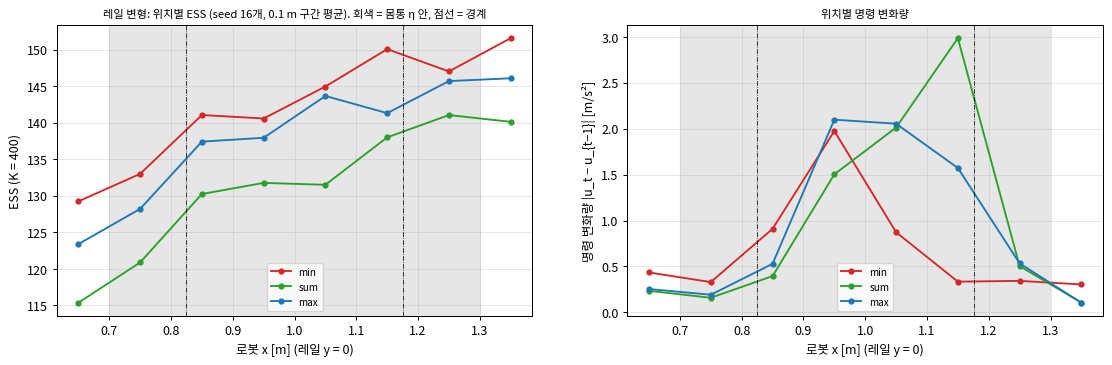

In [12]:
bins = np.arange(0.60, 1.401, 0.10)
xc = 0.5 * (bins[1:] + bins[:-1])
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2))
for m in MODES:
    X = np.concatenate([r['traj'][1:, 0] for r in RAIL[m]])
    E = np.concatenate([r['ess'] for r in RAIL[m]])
    D = np.concatenate([np.r_[0.0, np.abs(np.diff(r['us'][:, 0]))] for r in RAIL[m]])
    idx = np.digitize(X, bins) - 1
    ok = (idx >= 0) & (idx < len(xc))
    for ax, V in zip(axs, (E, D)):
        ax.plot(xc, [V[ok & (idx == b)].mean() if (ok & (idx == b)).any() else np.nan for b in range(len(xc))], 'o-', color=COL[m], ms=4, label=m)
x_in = xl[GL[:, 1] < ETA_T]
for ax, yl in zip(axs, ('ESS (K = 400)', '명령 변화량 |u_t − u_{t−1}| [m/s²]')):
    ax.axvspan(x_in.min(), x_in.max(), color='0.9', zorder=0)
    for i in sw:
        ax.axvline(xl[i], color='k', lw=0.6, ls='-.')
    ax.set_xlabel('로봇 x [m] (레일 y = 0)'); ax.set_ylabel(yl); ax.legend(fontsize=8)
axs[0].set_title('레일 변형: 위치별 ESS (seed 16개, 0.1 m 구간 평균). 회색 = 몸통 η 안, 점선 = 경계', fontsize=9)
axs[1].set_title('위치별 명령 변화량', fontsize=9)
plt.show()

**실제 경로가 η 안을 지났다.**
- η 안 스텝 비율은 0.05~0.06이다(실행마다 5~6스텝).
- 모든 실행이 경계를 두 번 넘었고, 모두 목표(x 1.98~2.03)에 도착했다.
- min 실행에서 경계를 넘기 직전 스텝의 몸통 비용과 손 비용 차이는 0.27~0.78이었다.

**가설 4는 반대 방향으로 나왔다.**

| seed 16개 평균 | min | max | sum |
|---|---|---|---|
| 경계 ±2스텝 ESS | 140.9 | 135.6 | 129.9 |
| 경계 ±2스텝 명령 변화량 [m/s²] | 0.61 | 0.66 | 0.68 |
| η 안 스텝 ESS | 142.8 | 138.3 | 132.4 |
| η 안 스텝 명령 변화량 [m/s²] | 0.79 | 1.06 | 1.12 |

같은 seed끼리 max와 비교한 결과:
- **min:** 경계 ±2스텝 ESS가 16 / 16에서 높았다(+2.5~+8.1). η 안 명령 변화량은 16 / 16에서 작았다(−0.05~−0.35). 경계 ±2스텝 명령 변화량은 평균 −0.05로, 16개 중 4개만 컸다.
- **sum:** ESS가 16 / 16에서 낮고(−4.6~−7.2), 명령 변화량은 16 / 16에서 컸다(+0.02~+0.08).

그림을 보면 다음과 같다.
- ESS는 모든 위치에서 min > max > sum이다. η 영역에 들어가기 전(x 0.65)부터 그렇다. 후보는 1.5 s 앞까지 보기 때문이다.
- 명령 변화량은 세 방식 모두 몸통 η 안에서 커진다. 그중 min은 x 1.0~1.2에서 0.88, 0.33으로 max(2.06, 1.57)보다 작다.

(해석) ESS의 순서 min > max > sum은 같은 자리의 비용 크기 순서(min ≤ max ≤ sum)와 반대이다. 17에서 비용 흩어짐이 클수록 ESS가 작았던 것과 같은 방향이다. min은 손이 가장 가까운 구간에서 몸통 비용이 빠져(2절의 홈) 비용이 작고, 그래서 그 구간을 더 매끄럽게 지나간 것으로 보인다. 이 레일 변형에서 min의 비용 뜀은 ESS를 줄이거나 명령을 흔들지 않았다.

**확인 문제 4b-1 (보기).** 4절의 2D 장면에서 σ를 줄여도 실제 경로가 η 안에 들어가지 않은 이유로 가장 알맞은 것은? (a) σ가 여전히 커서 (b) 옆으로 몇 cm 비켜 가는 목표 비용이 사람 비용보다 훨씬 작아서 (c) K가 작아서

<details><summary>답</summary>

**(b)**. σ = 0.5에서도 η 안 스텝이 0이었고, 목표를 η 안 (1.0, 0)에 두어도 로봇은 목표에서 9~10 cm 아래, η 밖에 멈췄다. 목표에서 조금 떨어져 있는 비용이 η 안에 들어가는 비용보다 작았다는 뜻이다. (a)는 σ = 0.5 결과로 맞지 않는다. (c)는 이 노트에서 확인하지 않았다.
</details>

## 4c. 후보의 30%가 뜀을 겪었는데 ESS가 같은 이유

**이것이 답하는 질문:** 4절에서 다가가는 동안 후보의 약 30%가 비용이 켜진 채 경계를 넘었다. 그런데 ESS는 min과 max에서 같았다. 왜 그런가?

17에서 ESS는 후보 비용의 흩어짐 s와 온도 β의 비 s/β로 정해졌다. 그러니 뜀 크기(2절의 0.750, 한 점의 비용)를 후보 비용의 표준편차, β와 나란히 놓아 본다. 후보 단위 값이 필요해서 18에서 추가한 `run_mpc_trace`를 쓴다. `run_mpc_opts`와 같은 계산을 하면서 반복마다 후보의 입력 U, 총비용 J, 가중치 w, 사람 비용 h를 넘겨준다. 4절의 min·max 실행(seed 8개)을 그대로 다시 돌려, 스텝마다 마지막 반복의 후보 400개를 본다.

또 같은 후보를 **min 비용으로 가중했을 때와 max 비용으로 가중했을 때**를 비교한다(반사실 가중: 후보는 그대로 두고 사람 비용만 바꿔 가중치를 다시 계산). 이렇게 하면 같은 상태, 같은 후보에서 합치는 방식만의 차이를 볼 수 있다.

구간은 둘이다. **다가가는 구간**(0~0.5 s)은 후보의 약 30%가 경계를 넘는 때다. **지나가는 구간**(0.5~1.0 s)은 실제 경로가 경계를 넘는 때다.

In [13]:
from common14.trace import run_mpc_trace

def plan_torso_gap(p, v, u):
    P, _ = rollout(p, v, u[None])
    return shape_gaps(P[0, 1:], SHAPES)[:, 1].min()

def cand_stats(mode):
    rows = []
    def cb(s, it, p, v, Pf, U, J, w, h):
        if it != S.N_ITERS - 1:
            return
        c, g = shape_costs(Pf, SHAPES)
        lab = g[..., 0] < g[..., 1]
        cmax = c.max(-1)
        cross = ((lab[:, 1:] != lab[:, :-1]) & ((cmax[:, 1:] > 0) | (cmax[:, :-1] > 0))).any(-1)
        shadow = (lab & (c[..., 1] > c[..., 0])).any(-1)
        h_min, h_max = combine_cost(Pf, Z, SHAPES, 'min').sum(-1), combine_cost(Pf, Z, SHAPES, 'max').sum(-1)
        J_goal = J - h
        w_min, w_max = softmax_weights(J_goal + h_min, S.BETA), softmax_weights(J_goal + h_max, S.BETA)
        u_min, u_max = np.einsum('k,k...->...', w_min, U), np.einsum('k,k...->...', w_max, U)
        K = len(J)
        nan = np.nan
        rows.append(dict(step=s, cross=cross.mean(), shadow=shadow.mean(), J_std=J.std(), h_std=h.std(), goal_std=J_goal.std(),
                         wK_cross=(w[cross] * K).mean() if cross.any() else nan, wK_rest=(w[~cross] * K).mean(),
                         ess_cf_min=1 / np.sum(w_min ** 2), ess_cf_max=1 / np.sum(w_max ** 2),
                         d_shadow=(h_min - h_max)[shadow].mean() if shadow.any() else nan,
                         wK_sh_min=(w_min[shadow] * K).mean() if shadow.any() else nan, wK_sh_max=(w_max[shadow] * K).mean() if shadow.any() else nan,
                         du_y=(u_min - u_max)[0, 1], d_gap=plan_torso_gap(p, v, u_min) - plan_torso_gap(p, v, u_max),
                         same_h=np.abs(h - (h_min if mode == 'min' else h_max)).max()))
    runs = [run_mpc_trace(partial(combine_cost, shapes=SHAPES, mode=mode), seed=s, on_iter=cb) for s in SEEDS]
    return rows, runs

t0 = time.time()
CS = {}
for mode in ('min', 'max'):
    rows, runs = cand_stats(mode)
    CS[mode] = {k: np.array([r[k] for r in rows]) for k in rows[0]}
    print('%s: run_mpc_trace와 4절 run_mpc_opts의 궤적 최대 차이 %.1e m, 기록한 h와 %s 비용의 최대 차이 %.1e'
          % (mode, max(np.abs(a['traj'] - b['traj']).max() for a, b in zip(runs, R4[(mode, 1)])), mode, CS[mode]['same_h'].max()))
print('실행 시간 %.0f s' % (time.time() - t0))
WIN = [('다가가는 구간 0~0.5 s', 0, 10), ('지나가는 구간 0.5~1.0 s', 10, 20)]
mean_in = lambda mode, k, a, b: np.nanmean(CS[mode][k][(CS[mode]['step'] >= a) & (CS[mode]['step'] < b)])

print('\n[4c] 뜀 크기 0.750(한 점), β = %.1f과 나란히' % S.BETA)
print('%-6s %-22s | %-10s | %-28s | %-24s | %s' % ('실행', '구간', '경계 넘는 후보', 'J 표준편차 (사람 몫 / 목표 몫)', '평균 가중치×K (넘는 / 나머지)', '같은 후보의 ESS (min 비용 / max 비용)'))
for mode in ('min', 'max'):
    for lbl, a, b in WIN:
        f = lambda k: mean_in(mode, k, a, b)
        print('%-6s %-22s | %-10.2f | %5.1f (%4.1f / %4.1f)            | %.2f / %.2f              | %.1f / %.1f'
              % (mode, lbl, f('cross'), f('J_std'), f('h_std'), f('goal_std'), f('wK_cross'), f('wK_rest'), f('ess_cf_min'), f('ess_cf_max')))

print('\n[4d] 그림자를 지나는 후보')
print('%-6s %-22s | %-10s | %-22s | %-26s | %-22s | %s' % ('실행', '구간', '그림자 후보', '그 후보의 min − max 비용', '그 후보의 가중치×K (min / max)', '첫 입력 u_y 차이 (min − max)', '평균 계획 몸통 간격 차이'))
for mode in ('min', 'max'):
    for lbl, a, b in WIN:
        f = lambda k: mean_in(mode, k, a, b)
        print('%-6s %-22s | %-10.2f | %+.2f                  | %.2f / %.2f                | %+.3f m/s²              | %+.2f cm'
              % (mode, lbl, f('shadow'), f('d_shadow'), f('wK_sh_min'), f('wK_sh_max'), f('du_y'), f('d_gap') * 100))
print('(u_y 차이가 양수 = min 가중치의 평균 입력이 사람 쪽(+y)으로 더 향함. 간격 차이가 음수 = min 가중치의 평균 계획이 몸통에 더 가까움)')

min: run_mpc_trace와 4절 run_mpc_opts의 궤적 최대 차이 0.0e+00 m, 기록한 h와 min 비용의 최대 차이 0.0e+00
max: run_mpc_trace와 4절 run_mpc_opts의 궤적 최대 차이 0.0e+00 m, 기록한 h와 max 비용의 최대 차이 0.0e+00
실행 시간 32 s

[4c] 뜀 크기 0.750(한 점), β = 1.0과 나란히
실행     구간                     | 경계 넘는 후보   | J 표준편차 (사람 몫 / 목표 몫)         | 평균 가중치×K (넘는 / 나머지)      | 같은 후보의 ESS (min 비용 / max 비용)
min    다가가는 구간 0~0.5 s        | 0.32       |  34.4 (28.8 / 11.0)            | 0.59 / 1.19              | 27.4 / 26.8
min    지나가는 구간 0.5~1.0 s      | 0.07       |  12.1 ( 2.2 / 11.4)            | 0.62 / 1.03              | 55.6 / 55.4
max    다가가는 구간 0~0.5 s        | 0.30       |  33.7 (27.9 / 11.0)            | 0.43 / 1.25              | 27.7 / 27.1
max    지나가는 구간 0.5~1.0 s      | 0.05       |  12.1 ( 2.2 / 11.4)            | 0.51 / 1.03              | 55.7 / 55.6

[4d] 그림자를 지나는 후보
실행     구간                     | 그림자 후보     | 그 후보의 min − max 비용     | 그 후보의 가중치×K (min / max)    | 첫 입력 u_y 차이 (min − max) | 평균 계획 몸통 간격 차이
min    다가가는 구간 0~0.5 s 

**경계를 넘는 후보는 처음부터 가중치가 작았다.** 다가가는 구간(0~0.5 s)에서 경계를 넘는 후보는 32%였다. 그 후보들의 평균 가중치는 평균의 0.59배, 나머지는 1.19배였다(min 실행, max 실행은 0.43 / 1.25).

**같은 후보를 min 비용과 max 비용으로 가중해도 ESS가 거의 같았다.** 다가가는 구간에서 27.4 / 26.8(min 실행), 27.7 / 27.1(max 실행)이었다. 지나가는 구간에서는 55.6 / 55.4였다.

**크기를 나란히 놓으면 다음과 같다.**

| 항목 | 값 |
|---|---|
| 뜀 크기 (한 점) | 0.750 |
| 그림자 후보의 총 사람 비용 차이 (min − max, 4d) | 평균 −1.10 |
| 온도 β | 1 |
| 후보 비용의 표준편차 (다가가는 구간) | 34.4 (사람 몫 28.8, 목표 몫 11.0) |

β = 1이므로 비용 1.1의 차이는 그 후보의 가중치를 약 e^1.1 ≈ 3배 바꿀 수 있다. 하지만 비용 차이는 후보 전체의 비용 표준편차보다 훨씬 작다.

(해석) 뜀을 겪는 후보는 사람 쪽으로 들어가는 후보라서 이미 비싸고 가중치가 작다. 그 비용이 1 정도 바뀌어도 가중치가 몰려 있는 싼 후보들의 구성은 거의 그대로다. 그래서 가중치가 몇 개 후보에 실려 있는지(ESS)는 바뀌지 않는다. 다만 표준편차 34.4는 사람에게 깊이 들어간 소수 후보의 큰 비용 때문에 커진 값이다. 정규분포라면 s/β = 34에서 ESS가 1에 가까워야 하는데 실제 ESS는 27이었다. 그러니 이 표준편차가 가중치를 받는 상위 후보들 사이의 흩어짐을 나타내지는 않는다. 상위 후보만의 흩어짐은 이 노트에서 따로 재지 않았다.

## 4d. min이 0.7 cm 가까이 지나간 이유 검증

**이것이 답하는 질문:** 4절에서 "(해석) 그림자를 지나는 후보는 min에서 몸통 비용이 빠져 더 싸게 보이고, 그래서 평균 계획이 덜 물러난다"고 적었다. 이것이 맞는가?

위 셀의 두 번째 표 [4d]를 본다. **그림자를 지나는 후보**는 손이 가장 가깝지만 몸통 비용이 더 큰 점을 하나라도 지나는 후보다.

**4절의 (해석)은 한 스텝 단위에서 확인됐다.**
- 다가가는 구간(0~0.5 s)에서 그림자를 지나는 후보는 29%였다. 그 후보들의 min 비용은 max 비용보다 평균 1.10 작았다(min 실행).
- 같은 후보를 min 비용으로 가중하면, 그 후보들의 평균 가중치가 평균의 0.49배(max 비용) → 0.63배(min 비용)로 커졌다.
- 그 결과 평균 입력이 사람 쪽(+y)으로 0.047 m/s² 더 향했다. 평균 계획의 몸통 최소 간격도 스텝마다 0.34 cm 작아졌다.
- 지나가는 구간(0.5~1.0 s)에서는 그림자 후보가 6%로 줄고, 간격 차이도 −0.01 cm로 거의 없었다.
- max 실행의 상태에서 같은 계산을 해도 방향이 같았다(+0.035 m/s², −0.30 cm). 어느 상태에서든 min 방식은 그림자 후보를 더 무겁게 쳐서 계획을 사람 쪽으로 기울였다.

**남는 (해석):** 다가가는 동안 생긴 한 스텝의 차이(약 −0.3 cm)가 다음 스텝으로 이어지는 계획(warm start)을 통해 쌓여, 실제 경로의 차이(평균 −0.72 cm)가 되었다고 본다. 이 누적 과정 자체는 직접 보이지 않았다.

**확인 문제 4d-1 (계산).** 그림자를 지나는 후보 하나가 min 비용으로 1.1만큼 싸게 보인다. β = 1이면, 다른 조건이 같을 때 이 후보의 가중치는 max 비용으로 볼 때의 몇 배인가?

<details><summary>답</summary>

가중치 ∝ exp(−J/β)이므로 exp(1.1/1) ≈ **3.0배**다(정규화 전, 다른 후보가 그대로일 때). 같은 후보 집합에서 그림자 후보만 이렇게 커지므로, 평균 계획이 그 후보들 쪽(사람 쪽)으로 기운다.
</details>

## 5. 정리

### 가설과 결과

| 가설 | 결과 |
|---|---|
| 1. min은 가장 가까운 형상이 바뀌는 선에서 뛰고, max와 sum은 이어진다 | **나옴.** 길 위에서 min은 0.750만큼 뛰었다. sum·max는 이웃 점 사이 0.0006 이하로 이어졌다. 추가로, max는 이어지지만 두 비용이 같아지는 곳에서 꺾였다(기울기 50.8 → 78.4). sum은 매끄러웠다 |
| 2. 몸통을 나누면 sum만 커지고 min·max는 그대로 | **나옴.** (1.0, 0)에서 sum 1.383 → 2.183 → 2.923(몸통 1 → 2 → 3개). min·max는 평면 전체에서 변화 0 |
| 3. MPPI에서 min이 몸통 그림자 때문에 더 가까이 지나간다 | **나옴, 작음.** 같은 seed 8 / 8에서 몸통 간격 −0.42~−1.03 cm. seed 범위는 겹침 |
| 4. min의 비용이 뛰는 곳 근처에서 ESS가 줄고 명령이 더 흔들린다 | **2D(4절)에서는 실제 경로가 η 밖이라 시험할 수 없었다.** 후보 수준에서도 뜀은 ESS를 바꾸지 않았다(같은 후보의 ESS 27.4 / 26.8, 4c). **레일 변형(4b, seed 16개)에서는 반대로 나왔다.** 경계 ±2스텝 ESS는 min 140.9 > max 135.6 > sum 129.9였다. η 안 명령 변화량은 min 0.79 < max 1.06 < sum 1.12였다 |

### 세 방식의 장단점 (이 노트의 장면)

| | min (가장 가까운 형상) | sum (모두 더하기) | max (가장 큰 비용) |
|---|---|---|---|
| 연속성 | **η가 다르면 경계에서 뜀**(길 위 0.750) | 연속, 매끄러움 | 연속, 비용이 같아지는 곳에서 꺾임 |
| 중복 계산 | 없음(나눠도 변화 0) | **있음**: 몸통 3개로 나누면 (1.0, 0)에서 1.383 → 2.923, 회피 +0.26 cm | 없음(나눠도 변화 0) |
| 몸통 그림자 | **있음**: 손이 가장 가까운 영역의 23%에서 더 큰 몸통 비용을 놓침, 회피 −0.7 cm | 없음 | 없음 |
| 계산량 | 간격은 모든 형상, η(μ)는 가장 가까운 형상 하나만 | 간격·η 모두 모든 형상 | 간격·η 모두 모든 형상 |
| MPPI 회피(같은 seed, max 기준) | 0.42~1.03 cm 가까움 | +0.05 cm(몸통 3개면 +0.26 cm) | 기준 |
| 경계 근처 ESS·명령 변화량 (4b 레일) | ESS 140.9, 명령 0.61 (η 안 0.79) | ESS 129.9, 명령 0.68 (η 안 1.12) | ESS 135.6, 명령 0.66 (η 안 1.06) |

세 성질(연속, 중복 계산 없음, 몸통 그림자 없음)을 모두 만족한 것은 **max뿐**이다. 이 장면에서 회피 차이는 1 cm 미만이었다. 그러니 max를 고르는 이유는 회피 결과보다 비용 지형의 성질에 있다. 몸을 어떻게 나누든 값이 같고, 무거운 부분의 큰 η가 가려지지 않으며, 끊기지 않는다.

- **max의 꺾임:** max는 이어지지만 두 비용이 같아지는 곳에서 꺾인다(기울기 50.8 → 78.4, 2절). MPPI는 후보의 비용 값만 쓰고 기울기를 쓰지 않아 영향이 없지만, 기울기 기반 최적화(예: cuRobo의 L-BFGS)에서는 다를 수 있다.
- **η 규칙:** 이 노트는 η ∝ μ(16의 (iii), p = 1)를 썼고, 프로젝트는 η ∝ √μ(p = 0.5)를 쓴다. 세 성질(연속성, 중복 계산, 그림자)은 p와 무관하다. 연속성과 그림자는 형상마다 η가 다르기만 하면(p > 0이면 손 η < 몸통 η) 생기고, 중복 계산은 η와 관계없이 형상 개수에서 생긴다. 아래 셀에서 p = 0.5로 바꿔 같은 지표를 다시 계산한다.

In [14]:
print('%-6s | %-8s | %-30s | %-30s | %s' % ('p', '손 η [m]', '길 위 min의 이웃 점 최대 변화 (뜀)', '손이 가장 가까운 영역 중 그림자 비율', '(1.0, 0)의 sum: 몸통 1 / 3개, min·max 변화'))
for pp in (1.0, 0.5):
    eh = ETA_T * (MU_H / MU_T) ** pp
    sh = [capsule(HAND['a'], HAND['b'], HAND['r'], eh, 'hand'), TORSO]
    sh3 = [sh[0]] + split_torso(3)
    jl = np.abs(np.diff(combine_cost(PL, (0.0, 0.0), sh, 'min'))).max()
    c, g = shape_costs(PG, sh)
    hn = free & (np.argmin(g, -1) == 0)
    shd = hn & (c[..., 1] > c[..., 0])
    s1, s3 = (float(combine_cost(P0, (0.0, 0.0), x, 'sum')) for x in (sh, sh3))
    dmm = max(np.abs(combine_cost(PG, (0.0, 0.0), sh3, m) - combine_cost(PG, (0.0, 0.0), sh, m))[free].max() for m in ('min', 'max'))
    print('%-6.1f | %-8.4f | %-30.3f | %-30s | %.3f / %.3f, %.1e' % (pp, eh, jl, '%.0f%% (%d / %d)' % (100 * shd.sum() / hn.sum(), shd.sum(), hn.sum()), s1, s3, dmm))

p      | 손 η [m]  | 길 위 min의 이웃 점 최대 변화 (뜀)        | 손이 가장 가까운 영역 중 그림자 비율          | (1.0, 0)의 sum: 몸통 1 / 3개, min·max 변화
1.0    | 0.0422   | 0.750                          | 23% (3545 / 15646)             | 1.383 / 2.923, 0.0e+00
0.5    | 0.0650   | 0.739                          | 9% (1383 / 15646)              | 2.356 / 3.895, 0.0e+00


p = 0.5이면 손 η가 0.0422 → 0.0650 m로 커져 손과 몸통의 대비가 줄어든다. 그래도 세 성질은 그대로였다.
- 길 위 min의 뜀은 0.739였다(p = 1: 0.750).
- 그림자는 손이 가장 가까운 영역의 9%로 줄었지만(p = 1: 23%) 남았다.
- 몸통을 3개로 나누면 sum만 2.356 → 3.895로 커지고, min·max는 변화가 0이었다.

크기는 p에 따라 달라지지만, 각 성질이 있고 없음은 p와 무관했다.

### 프로젝트와의 연결
프로젝트(franka-depth-mppi)는 형상 비용을 **max_all**(모든 형상의 비용 중 최댓값)로 합치는 것이 기본이다. **nearest**(가장 가까운 형상 하나)는 비교용이다. 이 노트의 결과로 보면, max_all은 nearest의 몸통 그림자와 비용 뜀이 없고 sum의 중복 계산도 없다. 대가는 계산량이다. 방향별 η를 쓰면 형상마다 μ를 계산해야 한다. **프로젝트 측정값**(Isaac Sim에서 측정, 이 노트에서는 재지 않음)으로 nearest는 +0.03 ms, max_all은 +0.79 ms가 더 걸렸다. max_all이 무거운 것은 형상 24개 모두의 μ를 계산하기 때문이다. 참고로 cuRobo의 충돌 비용은 장애물(형상)마다 비용을 더하는 sum이다. 사람 몸을 여러 형상으로 나눠 cuRobo 기본 방식에 넣으면 3절의 중복 계산이 생긴다.

**이 노트의 범위:** 장면 하나(손 + 몸통, 사람 정지), seed 8개, 형상마다 η 고정(방향별 η는 쓰지 않음), MPPI 기본 설정. 실행한 경로가 η 안을 지나는 경우는 로봇을 길 위에만 묶은 변형(4b, seed 16개)으로만 시험했다.

**확인 문제 5-1 (보기).** 형상 24개에 대해 방향별 η(형상마다 μ 계산)를 쓰는 프로젝트에서, nearest(min)가 max_all보다 계산이 가벼운 이유는? (a) 간격 계산을 하지 않아서 (b) μ(η)를 가장 가까운 형상 하나에 대해서만 계산하면 되어서 (c) MPPI 후보 수가 줄어서

<details><summary>답</summary>

**(b)**. 세 방식 모두 형상 24개의 간격은 다 계산해야 한다. min은 가장 가까운 형상 하나의 μ와 η만 계산하면 되지만, max와 sum은 모든 형상의 μ와 η가 필요하다.
</details>

## 핵심 정리

- 형상 비용을 합치는 방법은 셋이다. min(간격이 가장 작은 형상의 비용), sum(모두 더함, cuRobo 기본), max(가장 큰 비용).
- 형상마다 η가 같으면 min과 max는 같다. η가 다르면 min은 가장 가까운 형상이 바뀌는 선에서 값이 뛴다(이 장면의 길 위에서 0.750).
- **몸통 그림자:** 가벼운 손이 가장 가까우면 min은 바로 뒤 무거운 몸통의 더 큰 비용을 놓친다. 이 장면에서 손이 가장 가까운 영역의 23%가 그랬다.
- 연속 함수들의 최댓값은 연속이다. max는 끊기지 않지만 두 비용이 같아지는 곳에서 꺾인다. sum은 매끄럽다.
- **중복 계산:** 같은 몸을 더 많은 형상으로 나누면 sum만 커진다(몸통 3개로 나누면 1.383 → 2.923). min과 max는 그대로다.
- MPPI에서 min은 같은 seed 8 / 8에서 max보다 0.4~1.0 cm 가까이 지나갔다. sum은 나눈 개수에 따라 조금(최대 +0.26 cm) 멀어졌다. ESS와 명령 변화량은 같았다.
- 실제 경로가 η 안을 지나는 레일 변형(4b)에서도 min의 뜀은 ESS를 줄이거나 명령을 흔들지 않았다. ESS는 min > max > sum으로, 비용 크기의 반대 순서였다.
- 뜀을 겪는 후보는 원래 가중치가 작았다(평균의 0.59배). 그래서 같은 후보를 min과 max 어느 쪽으로 가중해도 ESS가 거의 같았다(4c). min이 더 가깝게 지나간 것은, 그림자 후보의 비용이 1.1 작게 매겨져 평균 계획이 사람 쪽으로 기울었기 때문이다(4d, 한 스텝에 −0.34 cm).
- 세 성질은 η 규칙의 지수 p와 무관하다. p = 0.5에서도 뜀은 0.739, 그림자는 9%로 남았고, 중복 계산도 그대로였다.
- max는 세 성질(연속, 중복 계산 없음, 그림자 없음)을 모두 만족한다. 대가는 모든 형상의 η(μ) 계산이다(프로젝트 측정값 +0.79 ms vs nearest +0.03 ms).

## 다음 노트

**19 · 필요 이격 거리** (작성 예정): 15~18에서 η와 비용 합치기를 정했다. 다음 노트에서는 사람에게 실제로 얼마나 떨어져야 하는지(필요 이격 거리)를 정하고 η와 비교한다.